# Bagging Exercises

# Цели обучения

- Установить связь между понятиями «бутстреппинга» и «агрегирования» (более известного как «баггинг») для снижения дисперсии
- Применять алгоритм «Случайного леса», который позволяет ещё больше снизить корреляцию, наблюдаемую в моделях, построенных методом баггинга


## Введение

Для выполнения заданий на этой неделе мы будем использовать данные об оттоке клиентов из телекоммуникационной отрасли, которые мы рассматривали на первой неделе. Файл данных называется `Orange_Telecom_Churn_Data.csv`.

In [1]:
from __future__ import print_function
import os
data_path = [ 'data']

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix



## Вопрос 1

* Импортируйте данные об оттоке клиентов, содержащиеся в файле `Orange_Telecom_Churn_Data.csv`.
* Удалите все столбцы, которые, вероятно, не будут использоваться для прогнозирования.
* Осуществите соответствующее кодирование типов данных.

В прогнозе ни в коем случае не должно фигурировать номер телефона. И вряд ли потребуются код города или штат, если только нет оснований полагать, что модель учитывает какой-то очень конкретный географический фактор.

Проанализируйте типы данных. Всё выглядит нормально, за исключением того, что `int_plan` и `voice_mail_plan` необходимо кодировать как булевы значения.

In [2]:
filepath = os.sep.join(data_path + ["Orange_Telecom_Churn_Data.csv"])
data = pd.read_csv(filepath)


data = data.drop(['state', 'area_code', 'phone_number'], axis=1)

for col in ['intl_plan', 'voice_mail_plan']:
    data[col] = data[col].map({'yes': True, 'no': False})

data['churned'] = data['churned'].astype(int)

print(data.dtypes)
data.head()

account_length                     int64
intl_plan                           bool
voice_mail_plan                     bool
number_vmail_messages              int64
total_day_minutes                float64
total_day_calls                    int64
total_day_charge                 float64
total_eve_minutes                float64
total_eve_calls                    int64
total_eve_charge                 float64
total_night_minutes              float64
total_night_calls                  int64
total_night_charge               float64
total_intl_minutes               float64
total_intl_calls                   int64
total_intl_charge                float64
number_customer_service_calls      int64
churned                            int64
dtype: object


,account_length,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,128,False,True,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,0
1,107,False,True,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,0
2,137,False,False,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,0
3,84,True,False,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,0
4,75,True,False,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,0


## Вопрос 2

* Проанализируйте распределение прогнозируемой переменной (`churned`).
* Разделите данные на обучающую и тестовую выборки. На основании распределения решите, следует ли использовать стратифицированное деление.
* Проанализируйте распределение предикторной переменной в обучающих и тестовых данных.

Учитывая асимметрию переменной-предиктора, давайте разбиваем данные, стратифицировав значения *churned*.

In [3]:
print(data['churned'].value_counts(normalize=True))

feature_cols = [c for c in data.columns if c != 'churned']  

splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, test_idx = next(splitter.split(data[feature_cols], data['churned']))

X_train = data.iloc[train_idx][feature_cols]
y_train = data.iloc[train_idx]['churned']
X_test = data.iloc[test_idx][feature_cols]
y_test = data.iloc[test_idx]['churned']

print('train:', y_train.value_counts(normalize=True).round(3).to_dict())
print('test: ', y_test.value_counts(normalize=True).round(3).to_dict())

churned
0    0.8586
1    0.1414
Name: proportion, dtype: float64
train: {0: 0.859, 1: 0.141}
test:  {0: 0.859, 1: 0.141}


## Вопрос 3

* Постройте модели «случайного леса» с различным количеством деревьев и оцените ошибку «out-of-bag» для каждой из этих моделей.
* Постройте график полученных ошибок «out-of-bag» в зависимости от количества деревьев.

*Подсказка:* поскольку изменяется только количество деревьев, можно использовать флаг `warm_start`, чтобы модель каждый раз просто добавляла новые деревья к существующей модели. Для обновления количества деревьев используйте метод `set_params`.

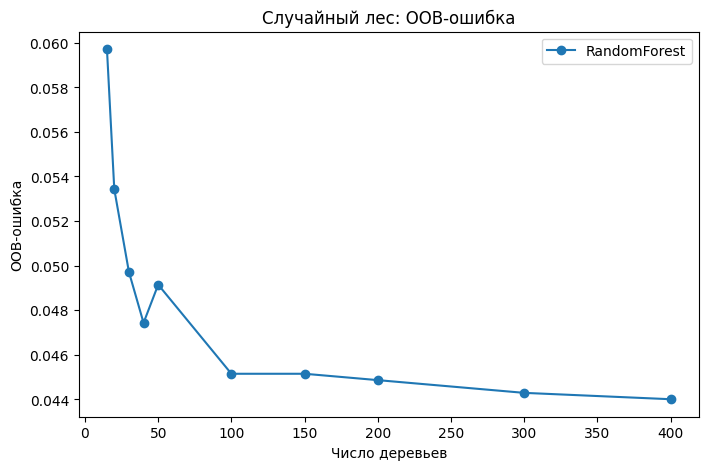

In [4]:

import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

RF = RandomForestClassifier(oob_score=True, random_state=42, warm_start=True, n_jobs=-1)

n_trees_list = [15, 20, 30, 40, 50, 100, 150, 200, 300, 400]
rf_oob = []

for n_trees in n_trees_list:
    RF.set_params(n_estimators=n_trees)      
    RF.fit(X_train, y_train)               
    rf_oob.append(1 - RF.oob_score_)         

rf_oob_df = pd.DataFrame({'n_trees': n_trees_list, 'RandomForest': rf_oob}).set_index('n_trees')

ax = rf_oob_df.plot(marker='o', figsize=(8, 5))
ax.set(ylabel='OOB-ошибка', xlabel='Число деревьев', title='Случайный лес: OOB-ошибка')
plt.show()

Похоже, что количество ошибок стабилизировалось на уровне 100–150 деревьев.

## Вопрос 4

* Повторите задание из вопроса 3, используя дополнительные рандомизированные деревья (`ExtraTreesClassifier`). Обратите внимание, что для этой модели параметр `bootstrap` необходимо установить в значение `True`.
* Сравните ошибки метода «out-of-bag» для двух различных типов моделей.

Объедините два датафрейма в один, чтобы упростить построение графиков.

Модель «случайного леса» демонстрирует стабильно более высокую эффективность по сравнению с моделью «дополнительных рандомизированных деревьев».

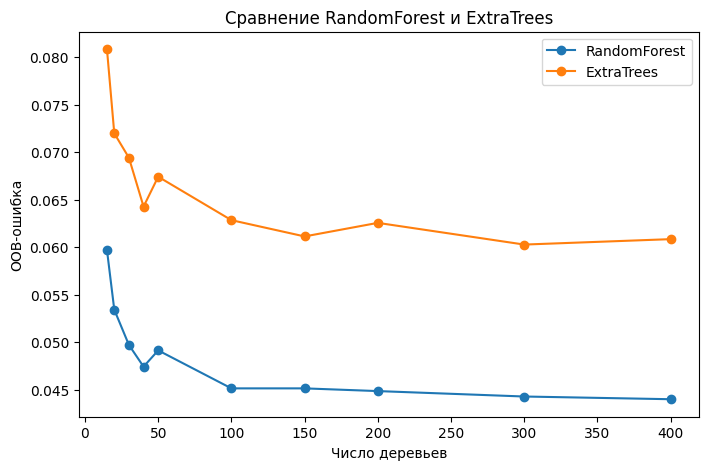

In [5]:
EF = ExtraTreesClassifier(oob_score=True, bootstrap=True, random_state=42,
                          warm_start=True, n_jobs=-1)

et_oob = []
for n_trees in n_trees_list:
    EF.set_params(n_estimators=n_trees)
    EF.fit(X_train, y_train)
    et_oob.append(1 - EF.oob_score_)


oob_df = rf_oob_df.copy()
oob_df['ExtraTrees'] = et_oob

ax = oob_df.plot(marker='o', figsize=(8, 5))
ax.set(ylabel='OOB-ошибка', xlabel='Число деревьев', title='Сравнение RandomForest и ExtraTrees')
plt.show()

## Вопрос 5

* Выберите одну из моделей, демонстрирующих хорошие результаты, и рассчитайте показатели ошибок и матрицу путаницы на тестовом наборе данных.
* Учитывая распределение предсказанных классов, какой показатель является наиболее важным? А какой может вводить в заблуждение?

Неудивительно, что показатель воспроизведения для класса «Ушедшие клиенты» (True) довольно низкий, поскольку их количество весьма невелико. Тем не менее, мы показываем лучшие результаты, чем при случайном угадывании: точность составляет 0,932 (против 0,85 при случайном угадывании).

In [6]:
model = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

y_pred = model.predict(X_test) 
y_prob = model.predict_proba(X_test)[:, 1]    

print(classification_report(y_test, y_pred))

metrics = pd.DataFrame({
    'accuracy':  [accuracy_score(y_test, y_pred)],
    'precision': [precision_score(y_test, y_pred)],
    'recall':    [recall_score(y_test, y_pred)],
    'f1':        [f1_score(y_test, y_pred)],
    'roc_auc':   [roc_auc_score(y_test, y_prob)],
}).round(3)
metrics

              precision    recall  f1-score   support

           0       0.96      0.99      0.98      1288
           1       0.94      0.78      0.85       212

    accuracy                           0.96      1500
   macro avg       0.95      0.89      0.92      1500
weighted avg       0.96      0.96      0.96      1500



,accuracy,precision,recall,f1,roc_auc
0,0.962,0.943,0.778,0.853,0.926


**Какая метрика важнее, а какая вводит в заблуждение?**

- **Accuracy (точность)** может вводить в заблуждение: 85% клиентов остаются, поэтому модель, которая *всегда* отвечает «останется», уже получит accuracy = 0.85.
- Важнее **recall** для класса «ушёл» (какую долю ушедших мы нашли) и **precision** (сколько из названных «уйдёт» действительно уходят), а также их среднее — **F1**.
  Для бизнеса обычно важнее не пропустить уходящих клиентов, то есть высокий recall.
- Recall по ушедшим получается невысоким, потому что их мало, но модель всё равно лучше случайного угадывания.

## Вопрос 6

* Распечатайте или отобразите матрицу путаницы.
* Постройте кривые ROC-AUC и точность-воспроизводимость.
* Постройте график важности признаков.

Кривые ROC-AUC и «точность-охватываемость».

Важность признаков. Общая ежедневная стоимость является наиболее значимым предиктором оттока клиентов.

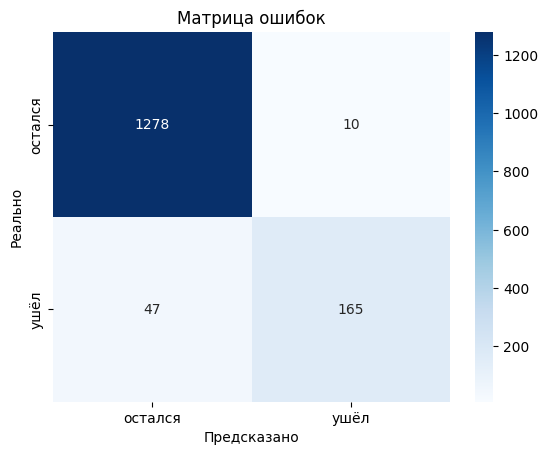

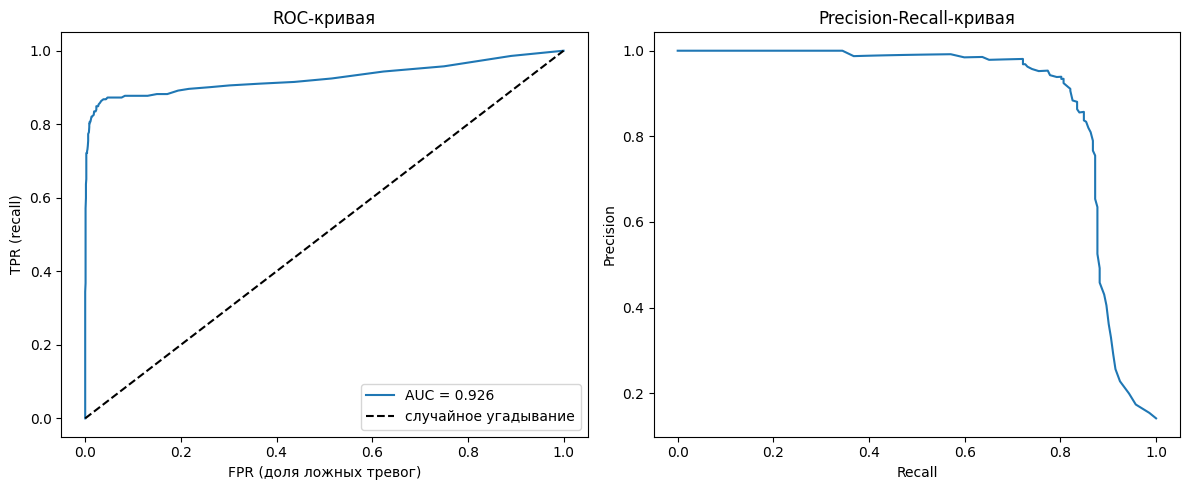

In [7]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['остался', 'ушёл'], yticklabels=['остался', 'ушёл'])
plt.xlabel('Предсказано')
plt.ylabel('Реально')
plt.title('Матрица ошибок')
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_prob)
precision, recall, _ = precision_recall_curve(y_test, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, y_prob):.3f}')
axes[0].plot([0, 1], [0, 1], 'k--', label='случайное угадывание')
axes[0].set(xlabel='FPR (доля ложных тревог)', ylabel='TPR (recall)', title='ROC-кривая')
axes[0].legend()

axes[1].plot(recall, precision)
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision-Recall-кривая')

plt.tight_layout()
plt.show()

### Важность признаков
Показывает, какие признаки лес использует сильнее всего.

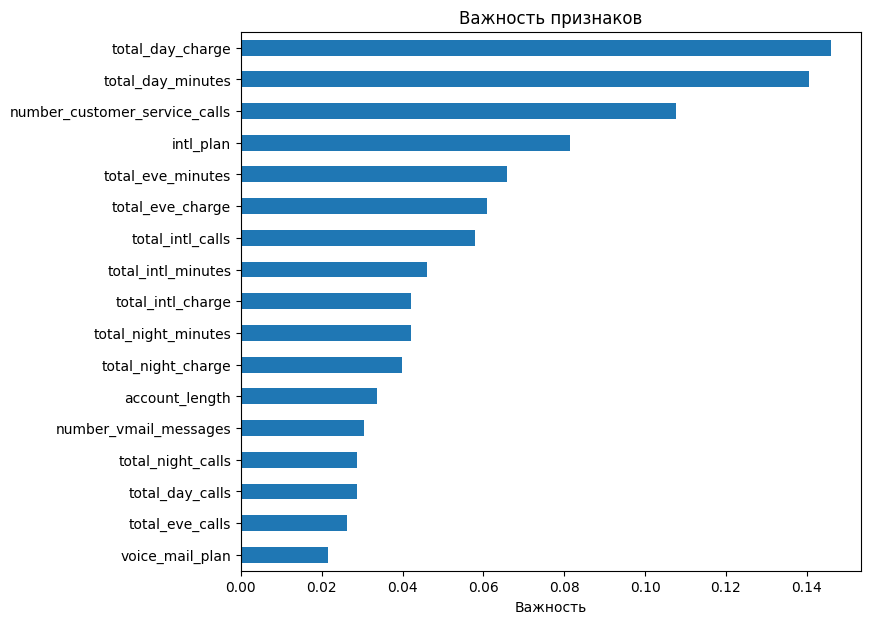

total_day_charge                 0.146095
total_day_minutes                0.140686
number_customer_service_calls    0.107719
intl_plan                        0.081321
total_eve_minutes                0.065913
dtype: float64


In [8]:
importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values()

importances.plot(kind='barh', figsize=(8, 7))
plt.xlabel('Важность')
plt.title('Важность признаков')
plt.show()

print(importances.sort_values(ascending=False).head(5))